# Model Training and Evaluation

This notebook trains and compares models for the two prediction tasks:

- Shipment Duration Prediction (regression): MAE, RMSE, R²
- Late Delivery Risk Prediction (classification): Accuracy, Precision, Recall, F1, ROC AUC

Models compared: Random Forest, XGBoost, Gradient Boosting, LightGBM

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor,
    RandomForestClassifier, GradientBoostingClassifier,
)
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor, XGBClassifier

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve

from lightgbm import LGBMClassifier
from lightgbm import LGBMRegressor

RANDOM_STATE = 42

In [23]:
def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def print_regression_metrics(title, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    r = rmse(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"\n=== {title} ===")
    print(f"MAE  : {mae:,.3f}")
    print(f"RMSE : {r:,.3f}")
    print(f"R²   : {r2:,.3f}")
    return mae, r, r2


def print_classification_metrics(title, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob) if y_prob is not None else None
    print(f"\n=== {title} ===")
    print(f"Accuracy : {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall   : {rec:.3f}")
    print(f"F1-score : {f1:.3f}")
    if auc is not None:
        print(f"ROC AUC  : {auc:.3f}")
    return acc, prec, rec, f1, auc

In [24]:
# Load splits produced by feature_engineering.ipynb
X_train_ship = pd.read_csv("../data/preprocessed/X_train_ship.csv")
X_test_ship = pd.read_csv("../data/preprocessed/X_test_ship.csv")
y_train_ship = pd.read_csv("../data/preprocessed/y_train_ship.csv").squeeze("columns")
y_test_ship = pd.read_csv("../data/preprocessed/y_test_ship.csv").squeeze("columns")

X_train_late = pd.read_csv("../data/preprocessed/X_train_late.csv")
X_test_late = pd.read_csv("../data/preprocessed/X_test_late.csv")
y_train_late = pd.read_csv("../data/preprocessed/y_train_late.csv").squeeze("columns")
y_test_late = pd.read_csv("../data/preprocessed/y_test_late.csv").squeeze("columns")

print("Shipping train/test:", X_train_ship.shape, X_test_ship.shape)
print("Late train/test:", X_train_late.shape, X_test_late.shape)

Shipping train/test: (144415, 11) (36104, 11)
Late train/test: (144415, 17) (36104, 17)


## Shipment Duration Prediction

Models: Random Forest, XGBoost, Gradient Boosting

In [25]:
# Random Forest - Shipment
rf_ship = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=4,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)
rf_ship.fit(X_train_ship, y_train_ship)
y_pred_rf_ship = rf_ship.predict(X_test_ship)

rf_mae, rf_rmse, rf_r2 = print_regression_metrics(
    "Shipment Random Forest", y_test_ship, y_pred_rf_ship
)


=== Shipment Random Forest ===
MAE  : 0.412
RMSE : 0.668
R²   : 0.831


In [26]:
# XGBoost - Shipment
xgb_ship = XGBRegressor(n_estimators=100, random_state=42)
xgb_ship.fit(X_train_ship, y_train_ship)
y_pred_xgb_ship = xgb_ship.predict(X_test_ship)

xgb_mae, xgb_rmse, xgb_r2 = print_regression_metrics(
    "Shipment XGBoost", y_test_ship, y_pred_xgb_ship
)


=== Shipment XGBoost ===
MAE  : 0.962
RMSE : 1.211
R²   : 0.443


In [27]:
# Gradient Boosting - Shipment
gb_ship = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=4,
    random_state=RANDOM_STATE
)
gb_ship.fit(X_train_ship, y_train_ship)
y_pred_gb_ship = gb_ship.predict(X_test_ship)

gb_mae, gb_rmse, gb_r2 = print_regression_metrics(
    "Shipment Gradient Boosting", y_test_ship, y_pred_gb_ship
)


=== Shipment Gradient Boosting ===
MAE  : 0.975
RMSE : 1.236
R²   : 0.421


In [28]:

lgb_ship = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)
lgb_ship.fit(X_train_ship, y_train_ship)
y_pred_lgb_ship = lgb_ship.predict(X_test_ship)

lgb_mae, lgb_rmse, lgb_r2 = print_regression_metrics(
    "Shipment LightGBM", y_test_ship, y_pred_lgb_ship
)



=== Shipment LightGBM ===
MAE  : 0.952
RMSE : 1.212
R²   : 0.443


In [29]:
shipment_results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost", "Gradient Boosting", "LightGBM"],
    "MAE":   [rf_mae,  xgb_mae,  gb_mae,  lgb_mae],
    "RMSE":  [rf_rmse, xgb_rmse, gb_rmse, lgb_rmse],
    "R2":    [rf_r2,   xgb_r2,   gb_r2,   lgb_r2],
}).sort_values(by="R2", ascending=False)

shipment_results


,Model,MAE,RMSE,R2
0,Random Forest,0.412196,0.668169,0.830633
1,XGBoost,0.961544,1.211463,0.443229
3,LightGBM,0.952159,1.211933,0.442797
2,Gradient Boosting,0.975333,1.235652,0.420774


In [30]:
best_shipment_model_name = shipment_results.iloc[0]["Model"]
print("Best Shipment model:", best_shipment_model_name)

Best Shipment model: Random Forest


In [31]:
# Train/test diagnostics for Random Forest
y_train_pred_rf_ship = rf_ship.predict(X_train_ship)

print("TRAIN METRICS")
print_regression_metrics("RF Train", y_train_ship, y_train_pred_rf_ship)

print("TEST METRICS")
print_regression_metrics("RF Test", y_test_ship, y_pred_rf_ship)

TRAIN METRICS

=== RF Train ===
MAE  : 0.184
RMSE : 0.308
R²   : 0.964
TEST METRICS

=== RF Test ===
MAE  : 0.412
RMSE : 0.668
R²   : 0.831


(0.4121960838393684, 0.6681688603036374, 0.8306331657946562)

In [32]:
# Cross-validation for Random Forest shipment model
X_ship_full = pd.concat([X_train_ship, X_test_ship], axis=0)
y_ship_full = pd.concat([y_train_ship, y_test_ship], axis=0)

cv_scores = cross_val_score(rf_ship, X_ship_full, y_ship_full, cv=5, scoring='r2')
print("CV R2 Scores:", cv_scores)
print("Mean CV R2:", cv_scores.mean())

CV R2 Scores: [0.83037531 0.82262127 0.82983634 0.83237366 0.83051687]
Mean CV R2: 0.8291446891227606


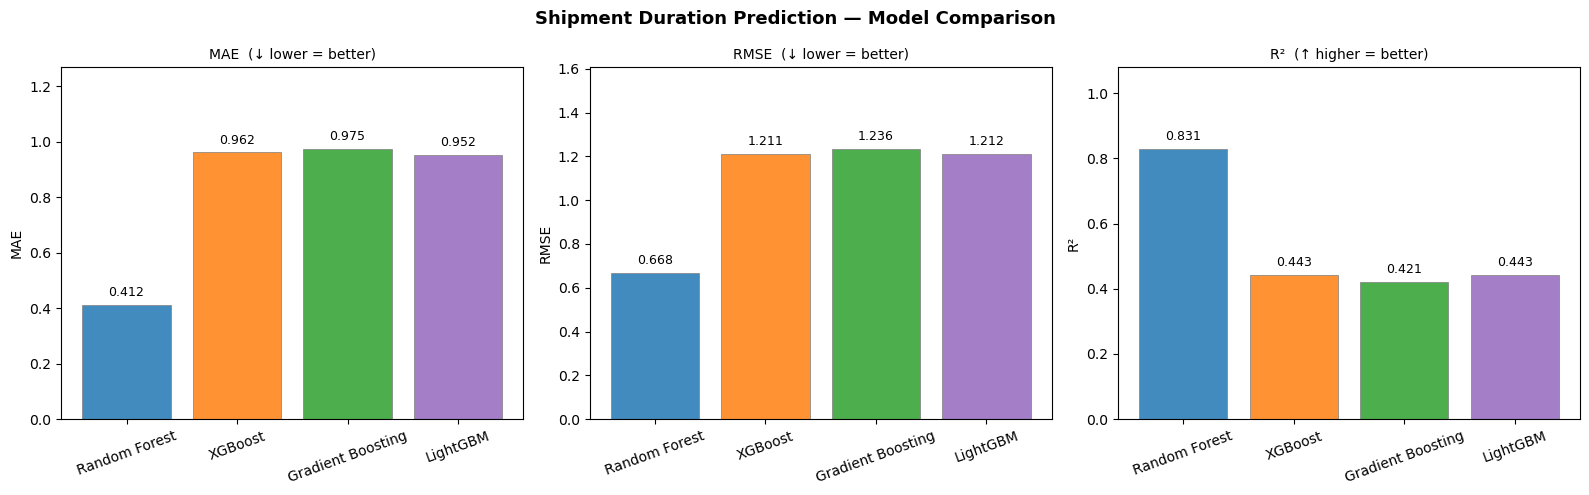

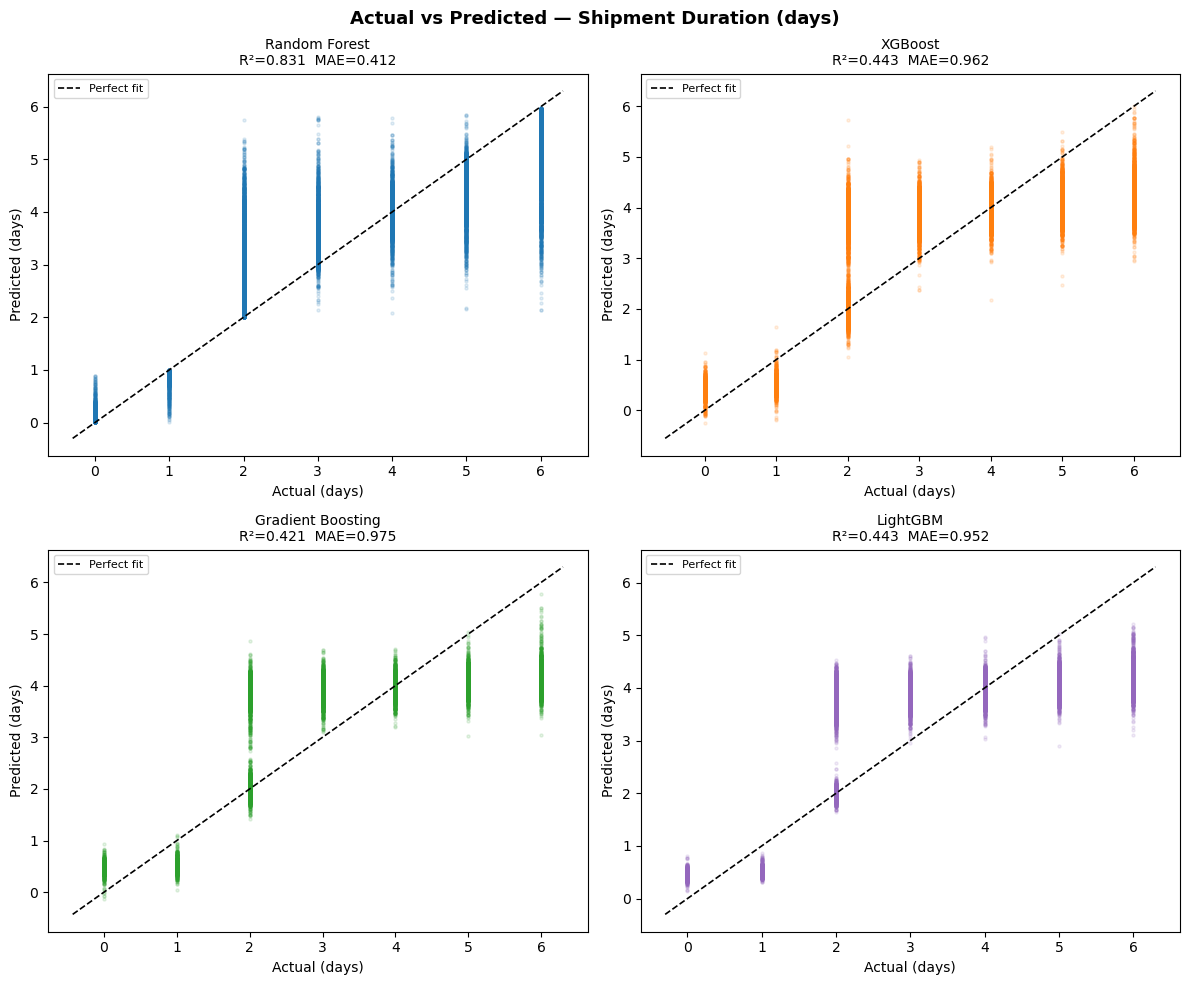

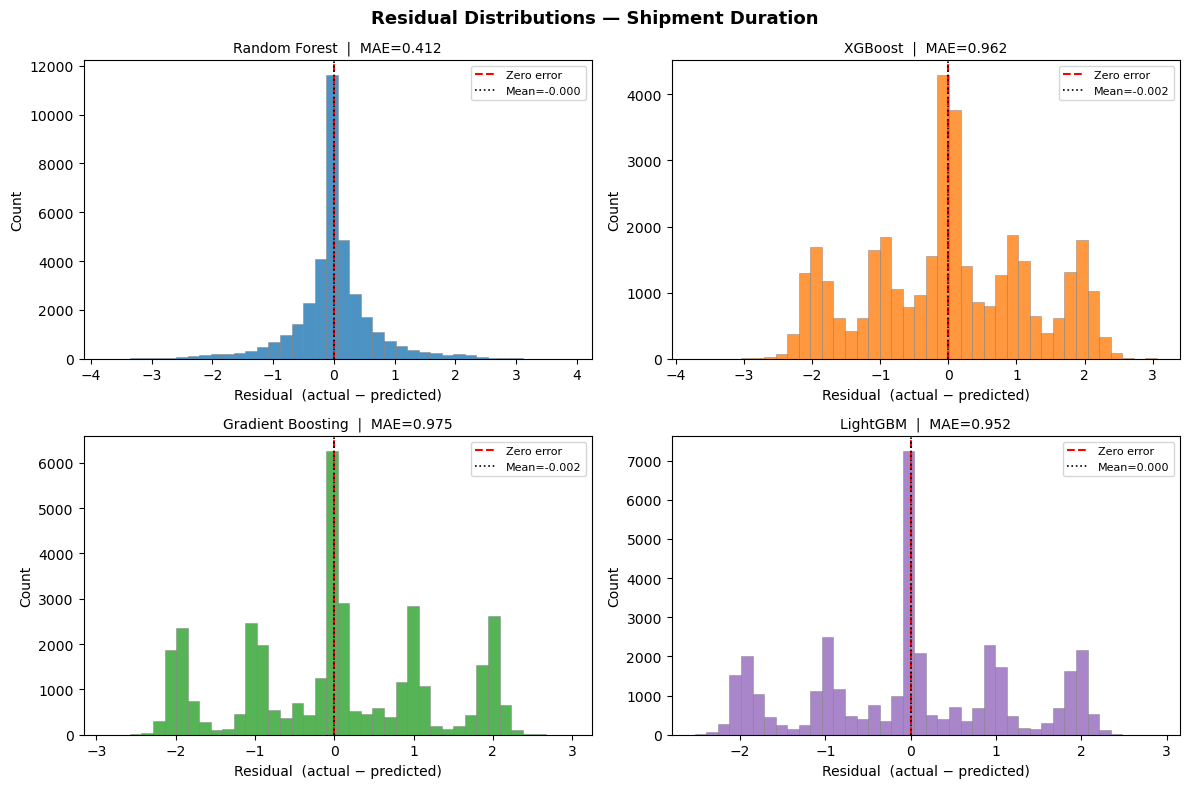

In [33]:
# ── shared palette ──────────────────────────────────────────────────────────
COLORS = {
    "Random Forest":     "#1f77b4",
    "XGBoost":           "#ff7f0e",
    "Gradient Boosting": "#2ca02c",
    "LightGBM":          "#9467bd",
}
MODEL_ORDER = ["Random Forest", "XGBoost", "Gradient Boosting", "LightGBM"]

sr = shipment_results.set_index("Model")

# ── 1. Grouped bar chart — MAE / RMSE / R² ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Shipment Duration Prediction — Model Comparison", fontsize=13, fontweight="bold")

metric_cfg = [
    ("MAE",  "MAE",  True),
    ("RMSE", "RMSE", True),
    ("R²",   "R2",   False),
]
for ax, (label, col, lower_better) in zip(axes, metric_cfg):
    vals = [sr.loc[m, col] for m in MODEL_ORDER]
    bars = ax.bar(MODEL_ORDER, vals, color=[COLORS[m] for m in MODEL_ORDER],
                  alpha=0.85, edgecolor="gray", linewidth=0.6)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
    direction = "↓ lower = better" if lower_better else "↑ higher = better"
    ax.set_title(f"{label}  ({direction})", fontsize=10)
    ax.set_ylabel(label)
    ax.set_ylim(0, max(vals) * 1.3)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

# ── 2. Actual vs Predicted scatter (2×2) ───────────────────────────────────
scatter_data = [
    ("Random Forest",     y_pred_rf_ship),
    ("XGBoost",           y_pred_xgb_ship),
    ("Gradient Boosting", y_pred_gb_ship),
    ("LightGBM",          y_pred_lgb_ship),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Actual vs Predicted — Shipment Duration (days)", fontsize=13, fontweight="bold")

for ax, (name, y_pred) in zip(axes.flatten(), scatter_data):
    ax.scatter(y_test_ship, y_pred, alpha=0.12, s=5, color=COLORS[name])
    lo = min(float(y_test_ship.min()), float(y_pred.min())) - 0.3
    hi = max(float(y_test_ship.max()), float(y_pred.max())) + 0.3
    ax.plot([lo, hi], [lo, hi], "k--", lw=1.2, label="Perfect fit")
    r2 = r2_score(y_test_ship, y_pred)
    mae = mean_absolute_error(y_test_ship, y_pred)
    ax.set_title(f"{name}\nR²={r2:.3f}  MAE={mae:.3f}", fontsize=10)
    ax.set_xlabel("Actual (days)")
    ax.set_ylabel("Predicted (days)")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── 3. Residual distributions (2×2) ────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Residual Distributions — Shipment Duration", fontsize=13, fontweight="bold")

for ax, (name, y_pred) in zip(axes.flatten(), scatter_data):
    residuals = np.array(y_test_ship) - np.array(y_pred)
    ax.hist(residuals, bins=40, color=COLORS[name], alpha=0.80, edgecolor="gray", linewidth=0.4)
    ax.axvline(0, color="red", lw=1.5, ls="--", label="Zero error")
    ax.axvline(residuals.mean(), color="black", lw=1.2, ls=":",
               label=f"Mean={residuals.mean():.3f}")
    mae_val = mean_absolute_error(y_test_ship, y_pred)
    ax.set_title(f"{name}  |  MAE={mae_val:.3f}", fontsize=10)
    ax.set_xlabel("Residual  (actual − predicted)")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## Late Delivery Risk Prediction

In [34]:
rf_late = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf_late.fit(X_train_late, y_train_late)
y_pred_rf_late = rf_late.predict(X_test_late)
y_prob_rf_late = rf_late.predict_proba(X_test_late)[:, 1]

rf_acc, rf_prec, rf_rec, rf_f1, rf_auc = print_classification_metrics(
    "Late Delivery Random Forest", y_test_late, y_pred_rf_late, y_prob_rf_late
)


=== Late Delivery Random Forest ===
Accuracy : 0.741
Precision: 0.870
Recall   : 0.620
F1-score : 0.724
ROC AUC  : 0.901


In [35]:
lgb_late = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)
lgb_late.fit(X_train_late, y_train_late)
y_pred_lgb_late = lgb_late.predict(X_test_late)
y_prob_lgb_late = lgb_late.predict_proba(X_test_late)[:, 1]

lgb_acc, lgb_prec, lgb_rec, lgb_f1, lgb_auc = print_classification_metrics(
    "Late Delivery LightGBM", y_test_late, y_pred_lgb_late, y_prob_lgb_late
)



=== Late Delivery LightGBM ===
Accuracy : 0.742
Precision: 0.868
Recall   : 0.625
F1-score : 0.727
ROC AUC  : 0.865


In [36]:
xgb_late = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric="logloss"
)
xgb_late.fit(X_train_late, y_train_late)
y_pred_xgb_late = xgb_late.predict(X_test_late)
y_prob_xgb_late = xgb_late.predict_proba(X_test_late)[:, 1]

xgb_acc, xgb_prec, xgb_rec, xgb_f1, xgb_auc = print_classification_metrics(
    "Late Delivery XGBoost", y_test_late, y_pred_xgb_late, y_prob_xgb_late
)


=== Late Delivery XGBoost ===
Accuracy : 0.744
Precision: 0.858
Recall   : 0.639
F1-score : 0.732
ROC AUC  : 0.843


In [37]:
gb_late = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=RANDOM_STATE
)
gb_late.fit(X_train_late, y_train_late)
y_pred_gb_late = gb_late.predict(X_test_late)
y_prob_gb_late = gb_late.predict_proba(X_test_late)[:, 1]

gb_acc, gb_prec, gb_rec, gb_f1, gb_auc = print_classification_metrics(
    "Late Delivery Gradient Boosting", y_test_late, y_pred_gb_late, y_prob_gb_late
)


=== Late Delivery Gradient Boosting ===
Accuracy : 0.722
Precision: 0.857
Recall   : 0.591
F1-score : 0.699
ROC AUC  : 0.792


In [38]:
late_results = pd.DataFrame({
    "Model":     ["Random Forest", "XGBoost", "Gradient Boosting", "LightGBM"],
    "Accuracy":  [rf_acc,  xgb_acc,  gb_acc,  lgb_acc],
    "Precision": [rf_prec, xgb_prec, gb_prec, lgb_prec],
    "Recall":    [rf_rec,  xgb_rec,  gb_rec,  lgb_rec],
    "F1 Score":  [rf_f1,   xgb_f1,   gb_f1,   lgb_f1],
    "ROC AUC":   [rf_auc,  xgb_auc,  gb_auc,  lgb_auc],
}).sort_values(by="ROC AUC", ascending=False)

late_results


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.740915,0.870389,0.619772,0.724006,0.900846
3,LightGBM,0.742328,0.867685,0.625429,0.726904,0.864881
1,XGBoost,0.743796,0.857831,0.638563,0.732133,0.842871
2,Gradient Boosting,0.721582,0.857290,0.590523,0.699330,0.791737


In [39]:
# Train/test diagnostics for late delivery RF
y_train_pred_rf = rf_late.predict(X_train_late)
y_train_prob_rf = rf_late.predict_proba(X_train_late)[:, 1]

print("TRAIN METRICS")
print_classification_metrics("RF Train", y_train_late, y_train_pred_rf, y_train_prob_rf)

print("TEST METRICS")
print_classification_metrics("RF Test", y_test_late, y_pred_rf_late, y_prob_rf_late)

TRAIN METRICS

=== RF Train ===
Accuracy : 0.767
Precision: 0.890
Recall   : 0.657
F1-score : 0.756
ROC AUC  : 0.945
TEST METRICS

=== RF Test ===
Accuracy : 0.741
Precision: 0.870
Recall   : 0.620
F1-score : 0.724
ROC AUC  : 0.901


(0.7409151340571681,
 0.87038876276958,
 0.6197716710446555,
 0.7240056650537,
 0.9008461887658333)

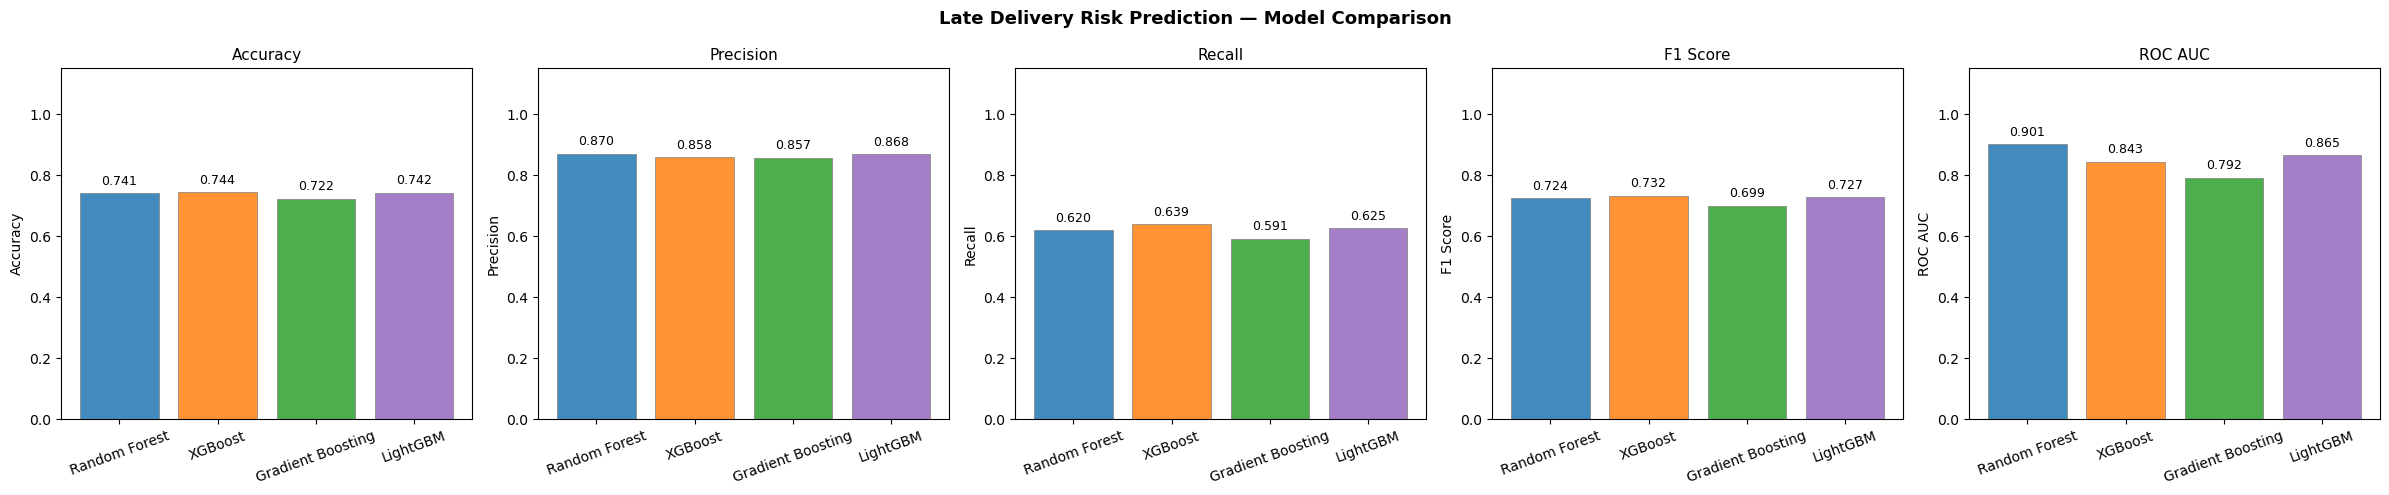

In [ ]:
lr = late_results.set_index("Model")

# ── 1. Grouped bar chart — Accuracy / Precision / Recall / F1 / ROC AUC ───
fig, axes = plt.subplots(1, 5, figsize=(24, 5))
fig.suptitle("Late Delivery Risk Prediction — Model Comparison", fontsize=13, fontweight="bold")

for ax, metric in zip(axes, ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]):
    vals = [lr.loc[m, metric] for m in MODEL_ORDER]
    bars = ax.bar(MODEL_ORDER, vals, color=[COLORS[m] for m in MODEL_ORDER],
                  alpha=0.85, edgecolor="gray", linewidth=0.6)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
    ax.set_title(metric, fontsize=11)
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.15)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


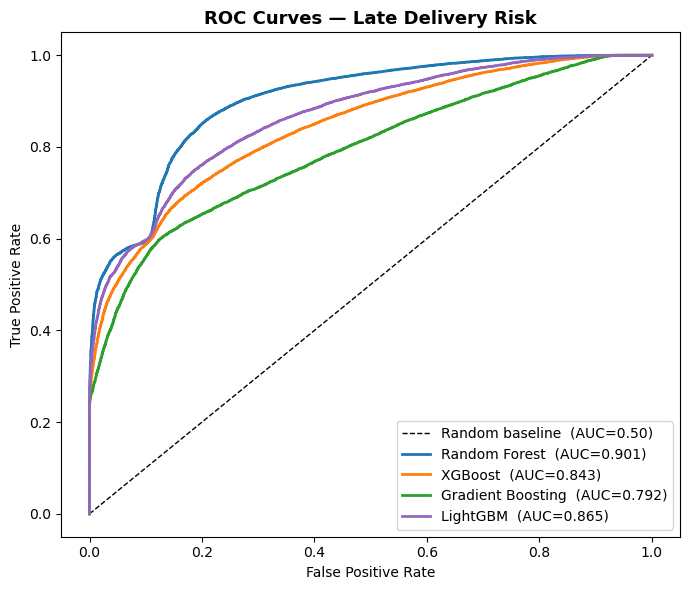

In [49]:
# ROC curves ───────────────────────────────────────────────────────────
clf_models = [
    ("Random Forest",     rf_late),
    ("XGBoost",           xgb_late),
    ("Gradient Boosting", gb_late),
    ("LightGBM",          lgb_late),
]

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random baseline  (AUC=0.50)")

for name, model in clf_models:
    y_prob = model.predict_proba(X_test_late)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_late, y_prob)
    auc = roc_auc_score(y_test_late, y_prob)
    ax.plot(fpr, tpr, color=COLORS[name], lw=2, label=f"{name}  (AUC={auc:.3f})")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Late Delivery Risk", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

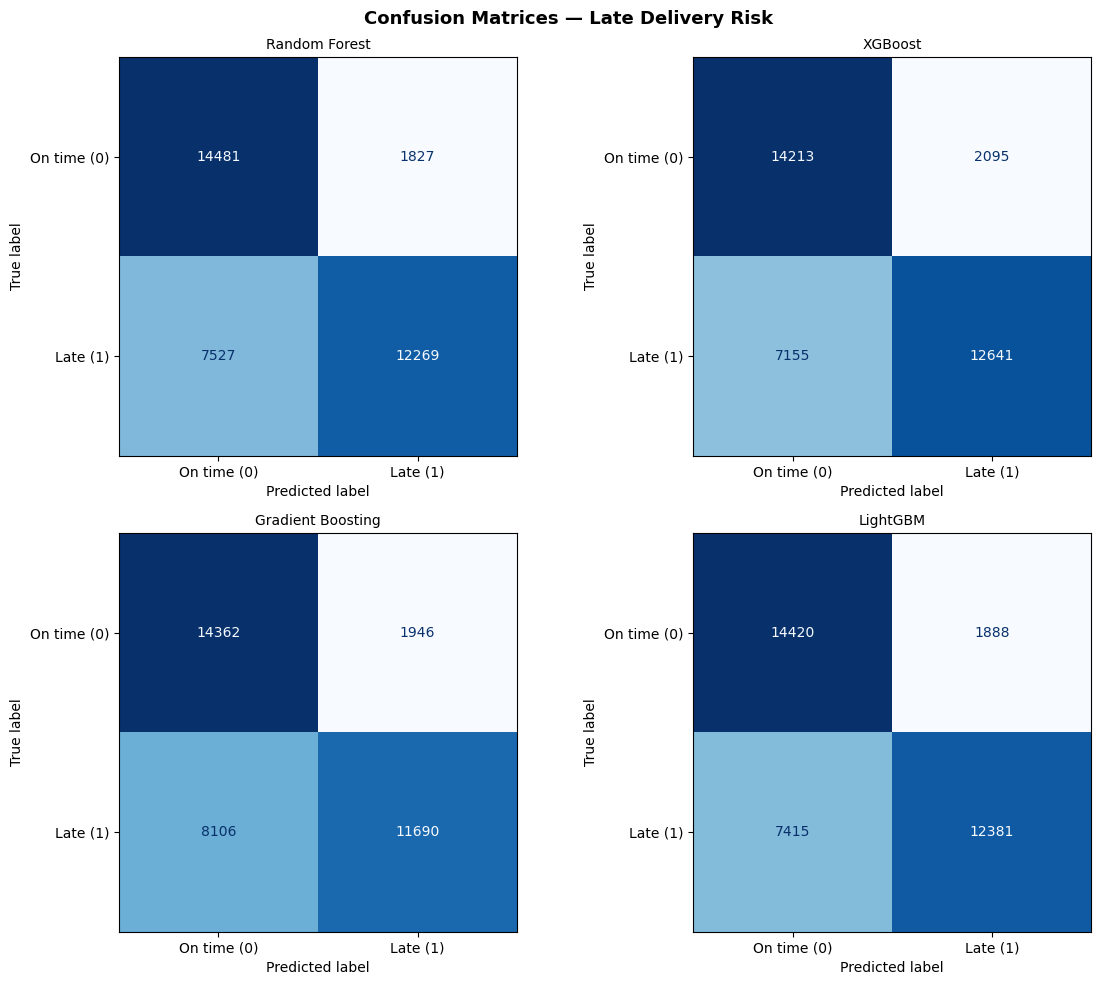

In [ ]:
#  Confusion matrices (2×2) ─────────────────────────────────────────────
clf_preds = [
    ("Random Forest",     rf_late,  y_pred_rf_late),
    ("XGBoost",           xgb_late, y_pred_xgb_late),
    ("Gradient Boosting", gb_late,  y_pred_gb_late),
    ("LightGBM",          lgb_late, y_pred_lgb_late),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Confusion Matrices — Late Delivery Risk", fontsize=13, fontweight="bold")

for ax, (name, model, y_pred) in zip(axes.flatten(), clf_preds):
    cm = confusion_matrix(y_test_late, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["On time (0)", "Late (1)"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    y_prob = model.predict_proba(X_test_late)[:, 1]
    auc = roc_auc_score(y_test_late, y_prob)
    ax.set_title(f"{name}", fontsize=10)

plt.tight_layout()
plt.show()    

### Confusion matrix analysis

- The False Negative Problem (Missed Lates):

    - We see that all models struggle with high False Negatives (FN), ranging from 7155 to 8106.

    - `XGBoost` performs best here, missing the fewest late deliveries (7155 FN), resulting in the highest Recall of 0.638.

    - `Gradient Boosting` is the weakest in this area, missing over 8000 late deliveries and having the lowest Recall at 0.590.

- The False Positive Problem (False Alarms):

    - `Random Forest` is the most conservative model, producing the fewest false alarms (1827 FP).

    - This gives Random Forest the highest Precision of 0.870, meaning when it flags a delivery as late, it is correct 87% of the time.

While `XGBoost` has the best `F1-Score` (0.732), Random Forest has a significantly higher `ROC AUC` of 0.900, higher ROC AUC suggests that the Random Forest model is actually better at distinguishing between the two classes across different probability thresholds.  

### Threshold Tuning — Random Forest

`XGBoost` is currently better at the default setting, but `Random Forest` has a higher **ceiling** for performance.By moving the threshold, we allow the `Random Forest` model to flag more deliveries as "Late." Because the model has such high discriminative power ($0.900$ AUC), it will likely pick up those 7527 missed deliveries faster than it picks up new false alarms.

In [48]:
# Sweep thresholds on Random Forest probabilities
thresholds = np.linspace(0.05, 0.95, 91)
rows = []
for t in thresholds:
    y_pred_t = (y_prob_rf_late >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Accuracy":  accuracy_score(y_test_late, y_pred_t),
        "Precision": precision_score(y_test_late, y_pred_t, zero_division=0),
        "Recall":    recall_score(y_test_late, y_pred_t, zero_division=0),
        "F1 Score":  f1_score(y_test_late, y_pred_t, zero_division=0),
    })
threshold_results = pd.DataFrame(rows)

best_f1_idx = threshold_results["F1 Score"].idxmax()
best_threshold = threshold_results.loc[best_f1_idx, "Threshold"]
best_row = threshold_results.loc[best_f1_idx]

print(f"Best threshold by F1: {best_threshold:.2f}")
print(f"  Accuracy : {best_row['Accuracy']:.3f}")
print(f"  Precision: {best_row['Precision']:.3f}")
print(f"  Recall   : {best_row['Recall']:.3f}")
print(f"  F1 Score : {best_row['F1 Score']:.3f}")


Best threshold by F1: 0.40
  Accuracy : 0.827
  Precision: 0.817
  Recall   : 0.881
  F1 Score : 0.848


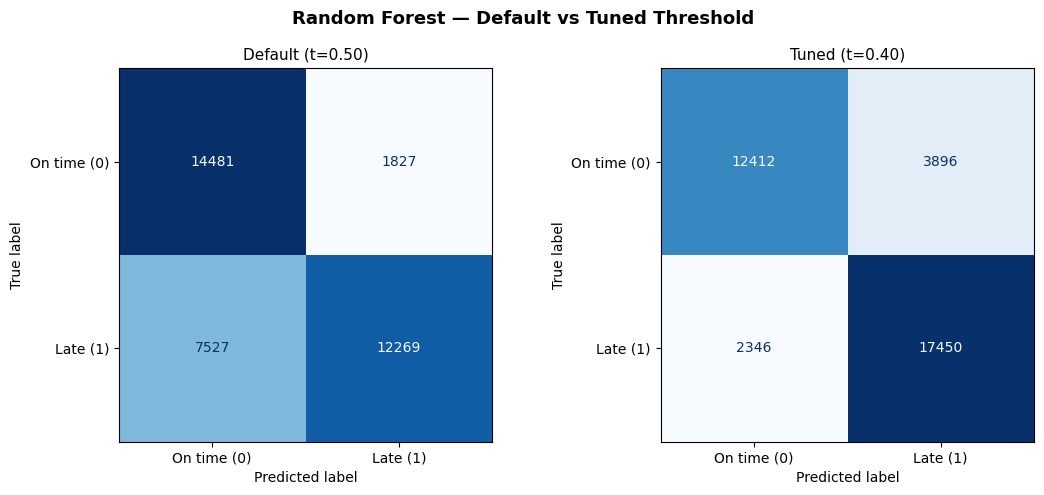

In [46]:
# ── Confusion matrix at tuned threshold ────────────────────────────────────
y_pred_rf_tuned = (y_prob_rf_late >= best_threshold).astype(int)
cm_tuned = confusion_matrix(y_test_late, y_pred_rf_tuned)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle("Random Forest — Default vs Tuned Threshold", fontsize=13, fontweight="bold")

for ax, (title, y_pred) in zip(axes, [
    ("Default (t=0.50)", y_pred_rf_late),
    (f"Tuned (t={best_threshold:.2f})", y_pred_rf_tuned),
]):
    cm = confusion_matrix(y_test_late, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["On time (0)", "Late (1)"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.show()

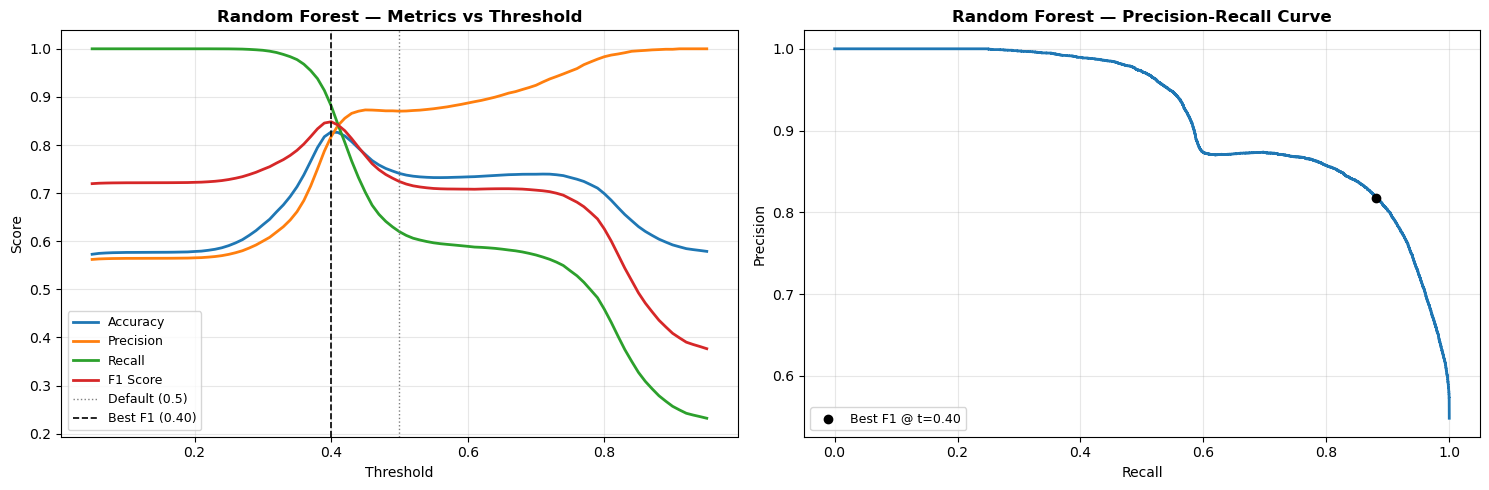

In [47]:
# ── Plot: metrics vs threshold ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
for metric, color in zip(["Accuracy", "Precision", "Recall", "F1 Score"],
                         ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]):
    ax.plot(threshold_results["Threshold"], threshold_results[metric],
            label=metric, color=color, lw=2)
ax.axvline(0.5, color="gray", ls=":", lw=1, label="Default (0.5)")
ax.axvline(best_threshold, color="black", ls="--", lw=1.2,
           label=f"Best F1 ({best_threshold:.2f})")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title("Random Forest — Metrics vs Threshold", fontsize=12, fontweight="bold")
ax.legend(loc="lower left", fontsize=9)
ax.grid(alpha=0.3)

# ── Plot: precision-recall curve ───────────────────────────────────────────
prec, rec, _ = precision_recall_curve(y_test_late, y_prob_rf_late)
ax = axes[1]
ax.plot(rec, prec, color="#1f77b4", lw=2)
ax.scatter(best_row["Recall"], best_row["Precision"], color="black", zorder=5,
           label=f"Best F1 @ t={best_threshold:.2f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Random Forest — Precision-Recall Curve", fontsize=12, fontweight="bold")
ax.legend(loc="lower left", fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Treshold-Tuning analysis

- Recall Improvement: Tuning the threshold to 0.40 increased the number of caught late deliveries (True Positives) from 12269 to 17450.

- Error Reduction: False Negatives (missed lates) were drastically reduced from 7,527 to 2,346, representing a significantly more proactive approach to logistics management.

- Precision Trade-off: As expected, False Positives increased from 1,827 to 3,896. However, the F1-Score plot confirms that $t=0.40$ is the mathematical "sweet spot" where the gain in Recall far outweighs the loss in Precision.

## Cross-Validation for Random Forest model

In [51]:
# Cross-validation for Random Forest late delivery model
X_late_full = pd.concat([X_train_late, X_test_late], axis=0)
y_late_full = pd.concat([y_train_late, y_test_late], axis=0)

cv_scores = cross_val_score(rf_late, X_late_full, y_late_full, cv=5, scoring='roc_auc')
print("CV ROC AUC:", cv_scores)
print("Mean CV ROC AUC:", cv_scores.mean())

CV ROC AUC: [0.90033689 0.8971841  0.90110435 0.89372625 0.90069625]
Mean CV ROC AUC: 0.8986095654087836


## Metrics Explanation

### Regression — Shipment Duration Prediction

| Metric | What it measures | Role |
|--------|-----------------|------|
| **MAE** | Average absolute error in days (e.g. 0.41 ≈ 10 hours off on average) | Primary **operational** metric which make it directly interpretable for logistics planning |
| **RMSE** | Like MAE but penalises large errors more heavily | Detects catastrophic mispredictions; if RMSE >> MAE, outlier errors are a problem |
| **R²** | Fraction of variance explained (0 = no better than the mean, 1 = perfect) | Primary **model-selection** metric it is unit-free, enables fair comparison across models |

---

### Classification — Late Delivery Risk Prediction

| Metric | What it measures | Role |
|--------|-----------------|------|
| **Accuracy** | % of predictions that are correct | Reference only because we have misleading with 55/45 class imbalance |
| **Precision** | Of all orders flagged late, how many actually were | Prioritise when **false alarms** are costly (alert fatigue in operations) |
| **Recall** | Of all truly late orders, how many were caught | Prioritise when **missing a late delivery** is costly (customer SLA breaches) |
| **F1** | Harmonic mean of Precision and Recall | Primary **model-selection** metric as it penalises sacrificing one for the other |
| **AUC-ROC** | Model ranking quality across all decision thresholds | Threshold-free evaluation we use it to tune the Precision/Recall tradeoff post-training without retraining |
